In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError, CategoricalCrossentropy

import os
import random
from datetime import datetime
import time
import math


import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-08-18 03:12:19.352983: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import importlib
import DAE_DataGenerator
import dataset_utils
import SoftQuantizeLayer
import AnnealingScheduler

importlib.reload(DAE_DataGenerator)
importlib.reload(dataset_utils)
importlib.reload(SoftQuantizeLayer)
importlib.reload(AnnealingScheduler)

from AnnealingScheduler import AnnealingScheduler
from DAE_DataGenerator import OptimizedDataGenerator
from dataset_utils import add_noise, quantize_manual
#from dataprep import *
# from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *


In [3]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

# dataset_dir_train = os.path.join(dataset_base_dir, "/dataset_3sr_16x16_50x12P5_parquets", 'train/')
# dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'train_contained/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'test_contained/')

# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'SQDAE_80eN_catgoricalOut_Target_0_7_23_134_404_867_1748')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_80eN_catgoricalOut_Target_0_7_23_134_404_867_1748')

tfrecords_dir_train   = os.path.join(tfrecords_base_dir, "TFR_train",'SQDAE_3srCI_240eN_catgoricalOut_Target_0_30_845')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_3srCI_240eN_catgoricalOut_Target_0_30_845')



# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'3sr_16x16_80eN_raw')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'3sr_16x16_80eN_raw')


print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_centeredIncidence_parquets/test_contained/


In [6]:
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    log_scale = False,
    select_contained = True,
    noise = [0,240],
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds= [0, 30, 845],
    # charge_thresholds= [0, 7, 23, 134, 404, 867, 1748],
    bitwise_categorical = True,
    # charge_thresholds = None,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
# validation_generator = [validation_generator[:][0], validation_generator[:][0]]

print("--- Validation generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:05<00:00,  3.68it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_240eN_catgoricalOut_Target_0_30_845 does not exist and cannot be removed.


Saving batches as TFRecords:   0%|          | 0/21 [00:00<?, ?it/s]2026-08-11 01:14:39.403362: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-11 01:14:39.446330: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-11 01:14:39.446812: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-11 01:14:39.448640: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To en

Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_240eN_catgoricalOut_Target_0_30_845/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_240eN_catgoricalOut_Target_0_30_845/metadata.json


--- Validation generator 15.933913469314575 seconds ---


In [ ]:
print(validation_generator[0][0][28][:,:,1])
print(np.argmax(validation_generator[0][1][28], axis = -1)[:,:,1])

In [6]:
print(validation_generator.dataset_logmax, validation_generator.dataset_logmin)

16.239303966535875 -11.77206435145071


In [7]:
# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    log_scale = False,
    labels_list = ['x-midplane','y-midplane','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0,40],
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds= [0, 30, 845],
    # charge_thresholds = [0, 7, 23, 134, 404, 867, 1748],
    bitwise_categorical = True,
    # charge_thresholds = None,

    # threshold = 400,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

# training_generator = [training_generator[:][0], training_generator[:][0]]

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 80/80 [00:21<00:00,  3.66it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_240eN_catgoricalOut_Target_0_30_845 does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 84/84 [00:39<00:00,  2.12it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_240eN_catgoricalOut_Target_0_30_845/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_240eN_catgoricalOut_Target_0_30_845/metadata.json


--- Training generator 62.78406023979187 seconds ---


In [16]:
#### Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    # seed=42,
    quantize=False,
    bitwise_categorical = True,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    # seed=42,
    quantize=False,
    bitwise_categorical = True,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_845_MEMTEST/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_845_MEMTEST/metadata.json


<class 'tensorflow.python.framework.ops.EagerTensor'>


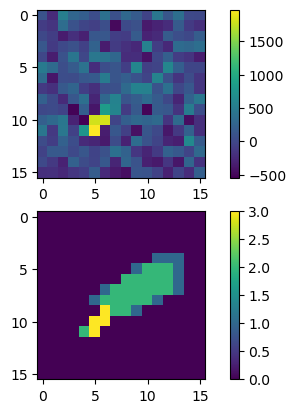

In [8]:
fig, ax = plt.subplots(2,1)
batch_index = 0
N = 18
ts = 0

print(validation_generator)

X_in = validation_generator[batch_index][0][N]
X_out = validation_generator[batch_index][1][N]


a = ax[0].imshow(X_in[:,:,ts]) 
fig.colorbar(a)
a = ax[1].imshow(np.argmax(X_out[:,:,ts,], axis = -1)) 
print(type(X_in))


fig.colorbar(a)


In [18]:
import loss
importlib.reload(loss)
from loss import CustomSSIMClass, CustomSSIM
import models
importlib.reload(models)
from models import *


model=CreateSQAutoencoder_Conv2D((16,16,2), n_filters=5, pool_size=3,
                        decoder_filters = 128, initial_thresholds=[10,80,800], 
                                     OutBits = 2, conv_kernel_size = 3)

#UNCOMMENT to Initialize from Weights
# weights_path = './SQ_DAE/model-9038a7c9-SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_856-checkpoints/'
# base_dir = weights_path
# checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
# best_weights = max(checkpoint_files, key=os.path.getmtime)
# print(f"Loading model from {best_weights}")
# model.load_weights(best_weights)


model.compile(
    # optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    optimizer=tf.keras.optimizers.Nadam(learning_rate=2e-3, clipnorm=1.0),
    # loss=MeanSquaredError()
    # loss=CustomSSIMClass(xrange = xrange, log_standardize = False),
    # loss=CustomSSIM(logxrange = xrange, 
    #                 log_standardize = True)
    loss = CategoricalCrossentropy(reduction = 'sum', from_logits=True
                                  )
    # run_eagerly=True
)

model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d (QSepara  (None, 14, 14, 5)        33        
 bleConv2D)                                                      
                                                                 
 q_activation (QActivation)  (None, 14, 14, 5)         0         
                                                                 
 q_conv2d (QConv2D)          (None, 14, 14, 5)         30        
                                                                 
 q_activation_1 (QActivation  (None, 14, 14, 5)        0     

In [19]:
from datetime import datetime
tname = 'SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_845_MEMORYTEST'#0_7_23_134_404_867_1748'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./SQ_DAE/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.4f}-v{val_loss:.4f}.hdf5'
print("fingerprint: ", fingerprint)

fingerprint:  63888c0a


In [20]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback
import csv

early_stopping_patience = 500

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

class SoftQuantizeLoggerCallback(Callback):
    def __init__(self, log_filepath, layer_name="soft_quantizer_output"):
        super().__init__()
        self.log_filepath = log_filepath
        self.layer_name = layer_name
        self.header_written = False

    def on_train_begin(self, logs=None):
        os.makedirs(os.path.dirname(self.log_filepath), exist_ok=True)

    def on_epoch_end(self, epoch, logs=None):
        try:
            layer = self.model.get_layer(self.layer_name)
            if not hasattr(layer, 'n_bits'):
                 print(f"\nWarning: Layer '{self.layer_name}' is not a SoftQuantizeLayer. Skipping logging.")
                 return
        except ValueError:
            print(f"\nWarning: Layer '{self.layer_name}' not found in the model. Skipping logging.")
            return

        if not self.header_written:
            num_levels = layer.num_levels
            num_thresholds = num_levels - 1
            
            header = ['epoch', 'k']
            # header.extend([f'level_{i}' for i in range(num_levels)])
            header.extend([f'threshold_{i}' for i in range(num_thresholds)])

            # header.append('raw_first_level')
            # header.extend([f'raw_log_level_delta_{i}' for i in range(num_levels - 1)])
            # header.append('raw_first_threshold')
            # if hasattr(layer, 'log_threshold_deltas'):
            #     header.extend([f'raw_log_threshold_delta_{i}' for i in range(num_thresholds - 1)])

            with open(self.log_filepath, mode='w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(header)
            self.header_written = True

        k_val = layer.k.numpy().item()
        # levels = layer.levels.numpy().tolist()
        thresholds = layer.thresholds.numpy().tolist()
        
        # first_level = layer.first_level.numpy().item()
        # log_level_deltas = layer.log_level_deltas.numpy().tolist()
        # first_threshold = layer.first_threshold.numpy().item()
        
        row_data = [epoch, k_val]
        # row_data.extend(levels)
        row_data.extend(thresholds)
        # row_data.append(first_level)
        # row_data.extend(log_level_deltas)
        # row_data.append(first_threshold)
        
        # if hasattr(layer, 'log_threshold_deltas'):
        #     log_threshold_deltas = layer.log_threshold_deltas.numpy().tolist()
        #     row_data.extend(log_threshold_deltas)
        
        with open(self.log_filepath, mode='a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow(row_data)


csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)
scheduler_callback = AnnealingScheduler(
    schedule='cosine',  
    target_layer_name='soft_quantizer_output', 
    initial_k=1.0,
    final_k=200.0, 
    verbose=1      
)

quantizer_logger = SoftQuantizeLoggerCallback(
    log_filepath=f"{base_dir}/soft_quantizer_state_log.csv", # New, more descriptive filename
    layer_name="soft_quantizer_output"
)

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)


In [21]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger,scheduler_callback, quantizer_logger],
        epochs=2000,
        shuffle=False,
        verbose=1
    )


Epoch 1: Annealing 'k' set to 1.0000
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 10.0000, 80.0001, 800.0002
	Tau: [ 40.00003 395.0001  720.0002 ]
Epoch 1/2000


2026-07-20 19:27:14.804492: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2026-07-20 19:27:14.821040: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800


 6/84 [=>............................] - ETA: 14s - loss: 2289681.7500WARNING:tensorflow:Callback method `on_train_batch_end` is slow compared to the batch time (batch time: 0.0739s vs `on_train_batch_end` time: 0.0965s). Check your callbacks.


84/84 [==============================] - ETA: 0s - loss: 779143.3750
Epoch 1: val_loss improved from inf to 551950.56250, saving model to ./SQ_DAE/model-63888c0a-SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_845_MEMORYTEST-checkpoints/weights.01-t779143.3750-v551950.5625.hdf5
84/84 [==============================] - 137s 2s/step - loss: 779143.3750 - val_loss: 551950.5625

Epoch 2: Annealing 'k' set to 1.0001
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 10.9804, 85.7870, 837.1307
	Tau: [ 42.893524 413.07516  751.3437  ]
Epoch 2/2000
84/84 [==============================] - ETA: 0s - loss: 514401.2500
Epoch 2: val_loss improved from 551950.56250 to 469386.25000, saving model to ./SQ_DAE/model-63888c0a-SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_845_MEMORYTEST-checkpoints/weights.02-t514401.2500-v469386.2500.hdf5
84/84 [==============================] - 18s 219ms/step - loss: 514401.2500 - val_loss: 469386.2500

Epoch 3: Annealing 'k' set to 1.0005
	Levels: 0.0000, 1.0000, 2.

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



...

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



84/84 [==============================] - ETA: 0s - loss: 178664.7500
Epoch 968: val_loss did not improve from 175304.18750
84/84 [==============================] - 20s 233ms/step - loss: 178664.7500 - val_loss: 187841.7656

Epoch 969: Annealing 'k' set to 95.5007
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 339.9176, 775.2461, 917.0026
	Tau: [387.62305 288.5425  141.75653]
Epoch 969/2000
84/84 [==============================] - ETA: 0s - loss: 178530.1562
Epoch 969: val_loss did not improve from 175304.18750
84/84 [==============================] - 19s 228ms/step - loss: 178530.1562 - val_loss: 185400.9688

Epoch 970: Annealing 'k' set to 95.6568
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 339.3212, 763.9582, 902.5901
	Tau: [381.9791  281.6345  138.63196]
Epoch 970/2000
84/84 [==============================] - ETA: 0s - loss: 178175.3438
Epoch 970: val_loss did not improve from 175304.18750
84/84 [==============================] - 22s 259ms/step - loss: 178175.3438 - v

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



84/84 [==============================] - ETA: 0s - loss: 178900.5938
Epoch 1343: val_loss did not improve from 173456.18750
84/84 [==============================] - 21s 244ms/step - loss: 178900.5938 - val_loss: 195809.1719

Epoch 1344: Annealing 'k' set to 151.5527
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 395.9728, 771.6959, 905.0111
	Tau: [385.84796 254.51917 133.31522]
Epoch 1344/2000
84/84 [==============================] - ETA: 0s - loss: 179476.3125
Epoch 1344: val_loss did not improve from 173456.18750
84/84 [==============================] - 23s 269ms/step - loss: 179476.3125 - val_loss: 180016.4219

Epoch 1345: Annealing 'k' set to 151.6868
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 395.4450, 777.2470, 912.5497
	Tau: [388.6235  258.55237 135.30273]
Epoch 1345/2000
84/84 [==============================] - ETA: 0s - loss: 178350.1094
Epoch 1345: val_loss did not improve from 173456.18750
84/84 [==============================] - 20s 235ms/step - loss: 178350

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [ ]:
'''Load weights and extract the encoder'''

import models
importlib.reload(models)
from models import CreateAutoEncoder

weights_path = './trained_models/DAE/model-e4177e22-DAE_80eNoise_5filters_convTranspose-checkpoints'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")
DAE=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3)
DAE.load_weights(latest_checkpoint)
model_summary = [[layer.name, layer.output.shape] for layer in DAE.layers]

# for layer in DAE.layers:
#     print(layer.name)

layer_name = DAE.layers[8].name 
# print(layer_name)
encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
encoder.trainable = False
encoder.summary()

print(encoder.output.shape)



In [ ]:
'''attach a dense regression network to the latent space'''
from models import var_network

x_in = encoder.input
lat_shape = encoder.output.shape
dense = var_network(encoder.output, hidden=16, output=14)
model = Model(inputs=x_in, outputs=dense)

model.summary()